In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn import preprocessing

from sklearn.pipeline import make_pipeline

#HYPERPARAMETERS
RANDOM_STATE = 42

In [2]:
#Read in data
df = pd.read_csv("../data/forest+fires/forestfires.csv", delimiter=",")

categorical_columns = ["month", "day"]
numerical_columns = ['X', 'Y', 'FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain']

In [3]:
#Add Engineered features
#Calculations used to get BUI and FWI are based off of https://publications.gc.ca/collections/collection_2016/rncan-nrcan/Fo133-1-424-eng.pdf

def addBUI(X):
    df = X.copy()
    #BUI
    dmc = df['DMC']
    dc = df['DC']

    buiLower = (0.8*dmc*dc)/(dmc+0.4*dc)
    buiHigher = dmc-(1.0-0.8*dc/(dmc+0.4*dc))*(0.92+(0.0114*dmc)**1.7)

    bui = np.where(dmc <= 0.4*dc, buiLower, buiHigher)

    df['BUI'] = bui
    return df

def addFWI(X):
    df = X.copy()
    #FWI
    isi = df['ISI']
    bui = df['BUI']

    fdLower = 0.626*bui**0.809 + 2.0
    fdHigher = 1000.0/(25.0+108.64*np.exp(-0.023*bui))
    Fd = np.where(bui <= 80, fdLower, fdHigher)

    b = 0.1*isi*Fd
    b = np.where(b<1, 1.0, b) #Safety so that we don't try to get log(0) in the next line
    fwi = np.where(b>0.1,np.exp(2.72*(0.434*np.log(b))**0.647),b)
    
    df['FWI'] = fwi
    return df

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, RobustScaler, OneHotEncoder, FunctionTransformer, StandardScaler
#Setting up Preprocessing Pipelines

categorical_pipe = make_pipeline(
    OneHotEncoder(handle_unknown="ignore")
)

numerical_pipe = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

preprocessing_all = make_pipeline(
    FunctionTransformer(addBUI),
    FunctionTransformer(addFWI),
    ColumnTransformer(
        [
            ("cat", categorical_pipe, categorical_columns),
            ("num", numerical_pipe, numerical_columns + ["BUI", "FWI"]),
        ]
    )
)

preprocessing_fire_weather_index = make_pipeline(
    FunctionTransformer(addBUI),
    FunctionTransformer(addFWI),
    ColumnTransformer(
        [
            ("num", numerical_pipe, ["FFMC", "DMC", "DC", "ISI", "BUI", "FWI"]),
        ]
    )
)

In [9]:
from sklearn.linear_model import LinearRegression, RidgeCV, GammaRegressor
from sklearn.dummy import DummyRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor

#Preprocessing and models that will be used

preprocessing_pipelines = {
    "ALL" : preprocessing_all,
    "FIRE WEATHER INDEX ONLY": preprocessing_fire_weather_index
}

models = {
    "Mean" : DummyRegressor(strategy="mean"),
    "Median" : DummyRegressor(strategy="median"),
    "Linear Regression": LinearRegression(),
    "Ridge" : RidgeCV(alphas=[0.01,0.1,1,10,100]),
    "KNN n = 3" : KNeighborsRegressor(n_neighbors=3), # Tried changing weights to "Distance", small negative impact on results
    "KNN n = 7" : KNeighborsRegressor(n_neighbors=7),
    "KNN n = 21" : KNeighborsRegressor(n_neighbors=21),
    "Random Forest": RandomForestRegressor(max_depth=2, random_state=RANDOM_STATE),
    "Random Forest 2": RandomForestRegressor(max_depth=5, random_state=RANDOM_STATE),
    "Random Forest 3": RandomForestRegressor(max_depth=10, random_state=RANDOM_STATE)
#    "Gamma Regressor": GammaRegressor() Doesn't work due to the 0s, normalisation fixes?
}

--------------PREPROCESSING:  ALL --------------
Model:  Mean 
Mean Absolute Error:  24.181393183088097 
Root Mean Squared Error:  108.90574106728259 
R2 Score:  -0.006167270424996207 


Model:  Median 
Mean Absolute Error:  19.64980769230769 
Root Mean Squared Error:  110.24190533688946 
R2 Score:  -0.031008054612458036 


Model:  Linear Regression 
Mean Absolute Error:  25.89461974854759 
Root Mean Squared Error:  108.19452109373057 
R2 Score:  0.006931572352040449 


Model:  Ridge 
Mean Absolute Error:  24.175752883280378 
Root Mean Squared Error:  108.34300353232852 
R2 Score:  0.00420399612720701 


Model:  KNN n = 3 
Mean Absolute Error:  25.295448717948716 
Root Mean Squared Error:  110.5895921856407 
R2 Score:  -0.037521607116518974 


Model:  KNN n = 7 
Mean Absolute Error:  25.09822802197802 
Root Mean Squared Error:  108.85613231311467 
R2 Score:  -0.005250820370011455 


Model:  KNN n = 21 
Mean Absolute Error:  23.972229853479856 
Root Mean Squared Error:  108.550880432062

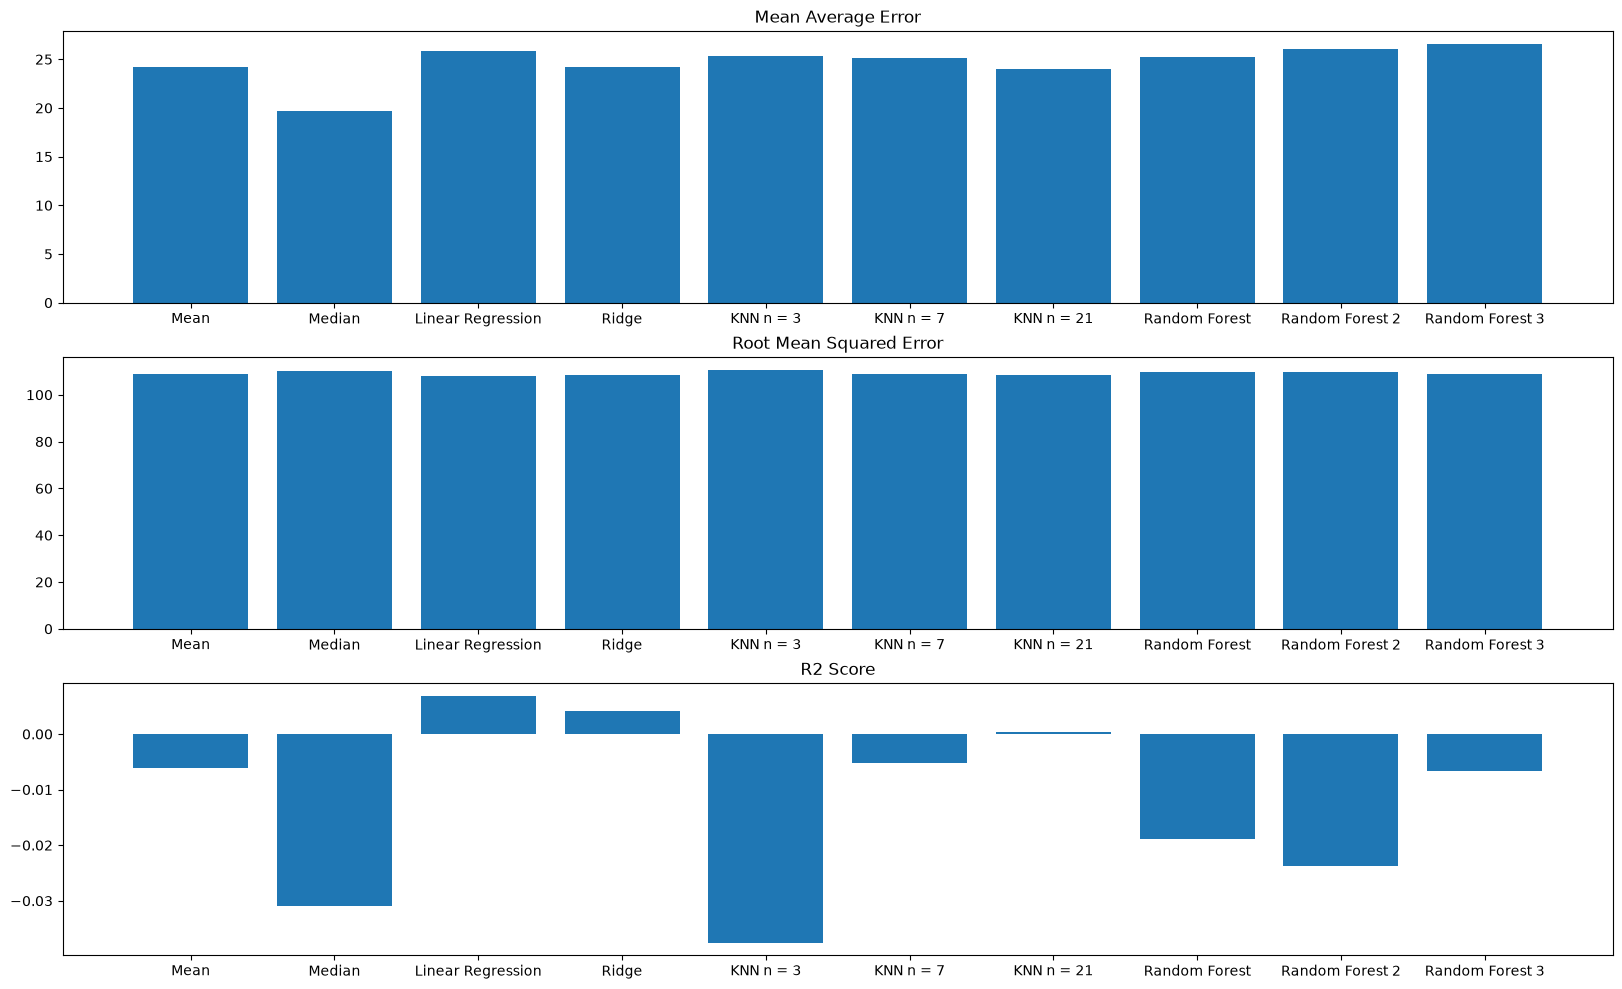

--------------PREPROCESSING:  FIRE WEATHER INDEX ONLY --------------
Model:  Mean 
Mean Absolute Error:  24.181393183088097 
Root Mean Squared Error:  108.90574106728259 
R2 Score:  -0.006167270424996207 


Model:  Median 
Mean Absolute Error:  19.64980769230769 
Root Mean Squared Error:  110.24190533688946 
R2 Score:  -0.031008054612458036 


Model:  Linear Regression 
Mean Absolute Error:  25.027377131157905 
Root Mean Squared Error:  109.30856095555973 
R2 Score:  -0.013624246555086428 


Model:  Ridge 
Mean Absolute Error:  24.444461147598645 
Root Mean Squared Error:  108.92395968390946 
R2 Score:  -0.006503937874448695 


Model:  KNN n = 3 
Mean Absolute Error:  20.430929487179487 
Root Mean Squared Error:  98.68127343207125 
R2 Score:  0.17388952827047477 


Model:  KNN n = 7 
Mean Absolute Error:  24.07269230769231 
Root Mean Squared Error:  105.2536963141644 
R2 Score:  0.060182885067668335 


Model:  KNN n = 21 
Mean Absolute Error:  24.44623626373626 
Root Mean Squared Error

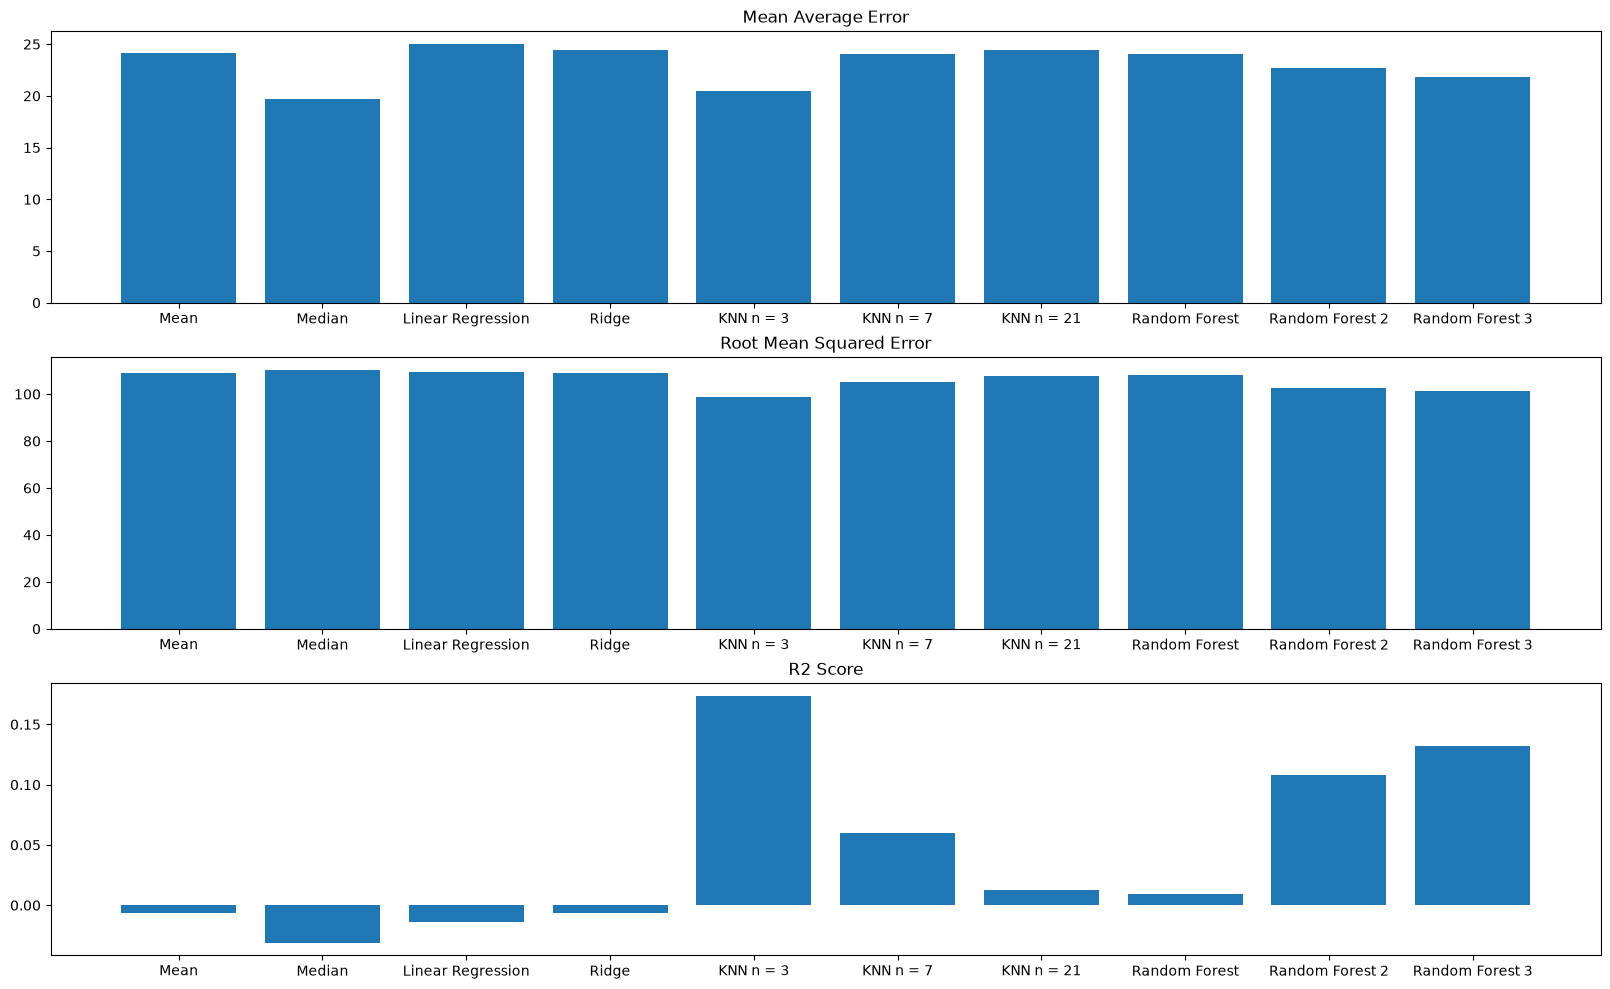

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
#Split the data
X = df[categorical_columns + numerical_columns]
y = no.log1p(df["area"])

# Trying Different Models and preprocessing pipelines using train test split


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=RANDOM_STATE)

for title, preprocessing in preprocessing_pipelines.items():
    print("--------------PREPROCESSING: ", title,"--------------")

    resultsMAE =[]
    resultsRMSE = []
    resultsR2 = []
    # Run all of the models and print out their results
    for name, model in models.items():
        model = make_pipeline(preprocessing, model)
        model.fit(X_train, y_train)
        pred = np.expm1(model.predict(X_test))

        mae = mean_absolute_error(y_test, pred)
        rmse = root_mean_squared_error(y_test, pred)
        r2 = r2_score(y_test, pred)
    
        resultsMAE.append(mae)
        resultsRMSE.append(rmse)
        resultsR2.append(r2)
    
        print("Model: ", name ,"\nMean Absolute Error: ", mae, "\nRoot Mean Squared Error: ", rmse,"\nR2 Score: ", r2 ,"\n\n")

    #Plot Results
    plt.figure(figsize={len(models.keys()) * 2,12}) ##Figure is dynamically sized to allow for more models to be added as needed
    
    plt.subplot(311, title="Mean Average Error").bar(range(len(resultsMAE)),resultsMAE)
    plt.xticks(range(len(models.keys())),models.keys())
    
    plt.subplot(312, title="Root Mean Squared Error").bar(range(len(resultsRMSE)),resultsRMSE)
    plt.xticks(range(len(models.keys())),models.keys())
    
    plt.subplot(313, title="R2 Score").bar(range(len(resultsR2)),resultsR2)
    plt.xticks(range(len(models.keys())),models.keys())

    plt.show()

Median seems like the best baseline when ran against all columns, very low R2 score though

KNN n = 3 gets a much better R2 Score when ran using only the FWI values

--------------PREPROCESSING:  ALL --------------
Model:  Mean 
Mean Absolute Error:  18.601950948884948 
Root Mean Squared Error:  46.59387426339114 
R2 Score:  -0.11840109852428118 


Model:  Median 
Mean Absolute Error:  12.844220085470091 
Root Mean Squared Error:  47.55444633886254 
R2 Score:  -0.12741721353976457 


Model:  Linear Regression 
Mean Absolute Error:  21.911640601884447 
Root Mean Squared Error:  49.5869109227956 
R2 Score:  -0.6669147869298209 


Model:  Ridge 
Mean Absolute Error:  19.497670181465374 
Root Mean Squared Error:  47.614962056960636 
R2 Score:  -0.31859027235413395 


Model:  KNN n = 3 
Mean Absolute Error:  21.31807771912185 
Root Mean Squared Error:  60.85146047845941 
R2 Score:  -3.737250145853587 


Model:  KNN n = 7 
Mean Absolute Error:  20.05388914027151 
Root Mean Squared Error:  54.49169900056805 
R2 Score:  -1.6191345453441424 


Model:  KNN n = 21 
Mean Absolute Error:  19.628108818741183 
Root Mean Squared Error:  50.1509570595459 
R2 Score:

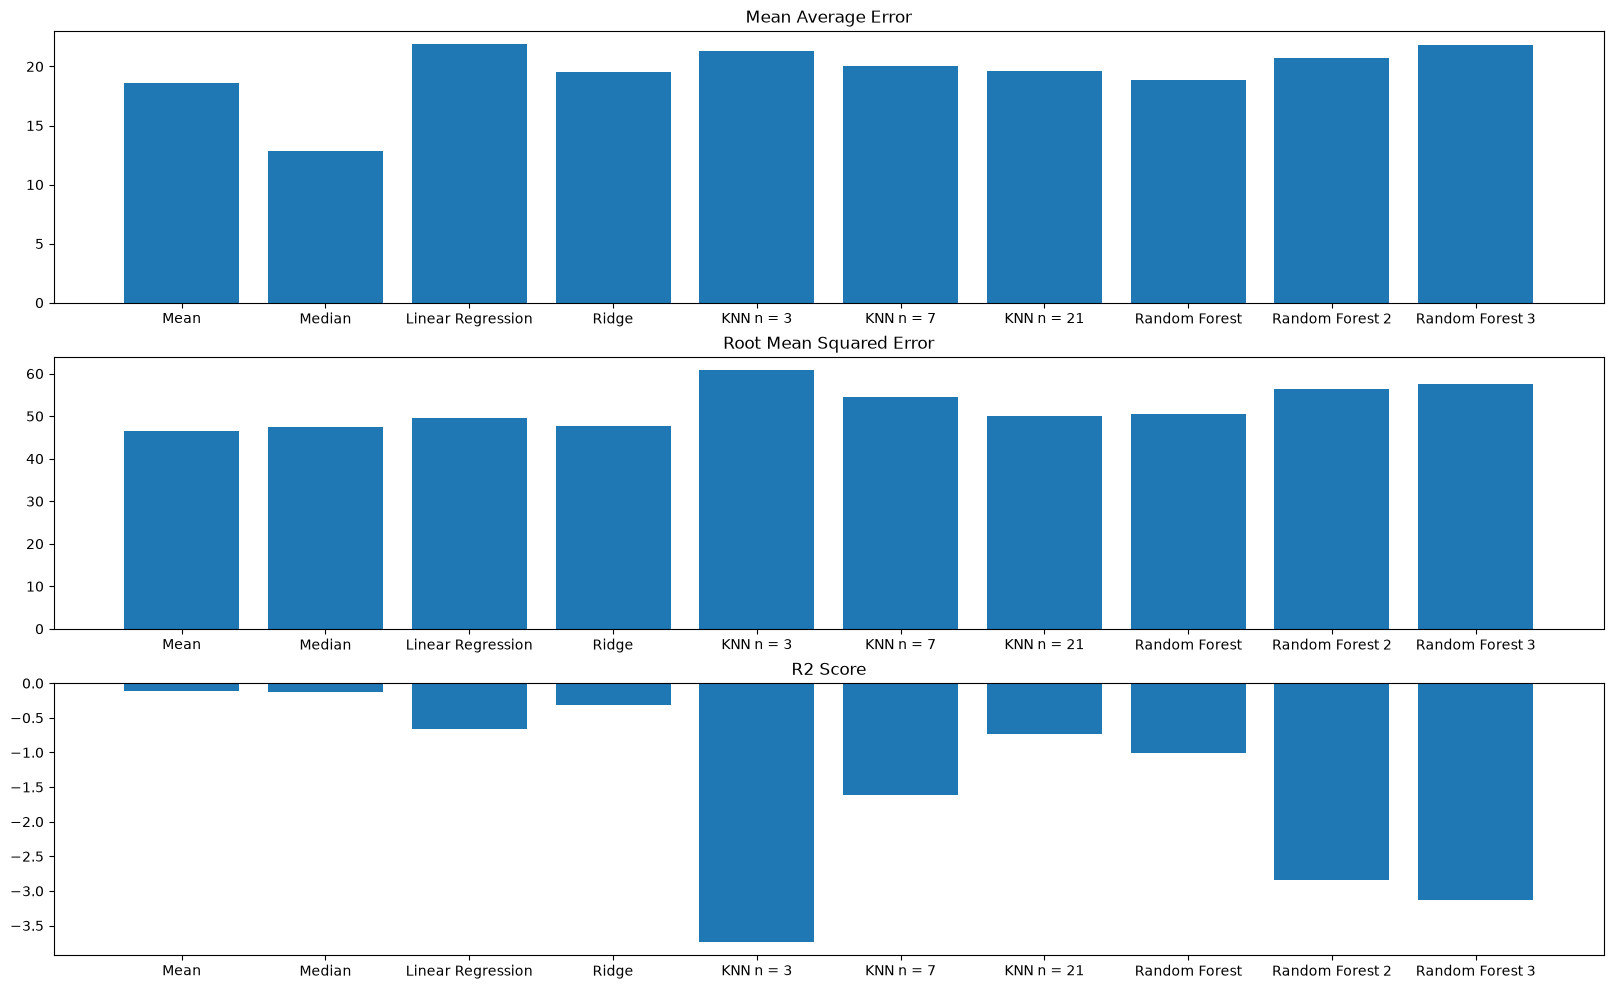

--------------PREPROCESSING:  FIRE WEATHER INDEX ONLY --------------
Model:  Mean 
Mean Absolute Error:  18.601950948884948 
Root Mean Squared Error:  46.59387426339114 
R2 Score:  -0.11840109852428118 


Model:  Median 
Mean Absolute Error:  12.844220085470091 
Root Mean Squared Error:  47.55444633886254 
R2 Score:  -0.12741721353976457 


Model:  Linear Regression 
Mean Absolute Error:  19.06754069608248 
Root Mean Squared Error:  47.01533088335652 
R2 Score:  -0.19815277373234377 


Model:  Ridge 
Mean Absolute Error:  18.776508847136522 
Root Mean Squared Error:  46.70365023266131 
R2 Score:  -0.15716489134618683 


Model:  KNN n = 3 
Mean Absolute Error:  20.446447628624114 
Root Mean Squared Error:  60.66424971937213 
R2 Score:  -4.694377897276357 


Model:  KNN n = 7 
Mean Absolute Error:  20.819556920203993 
Root Mean Squared Error:  56.35431038773827 
R2 Score:  -2.7719135424285173 


Model:  KNN n = 21 
Mean Absolute Error:  19.64617591994064 
Root Mean Squared Error:  50.205

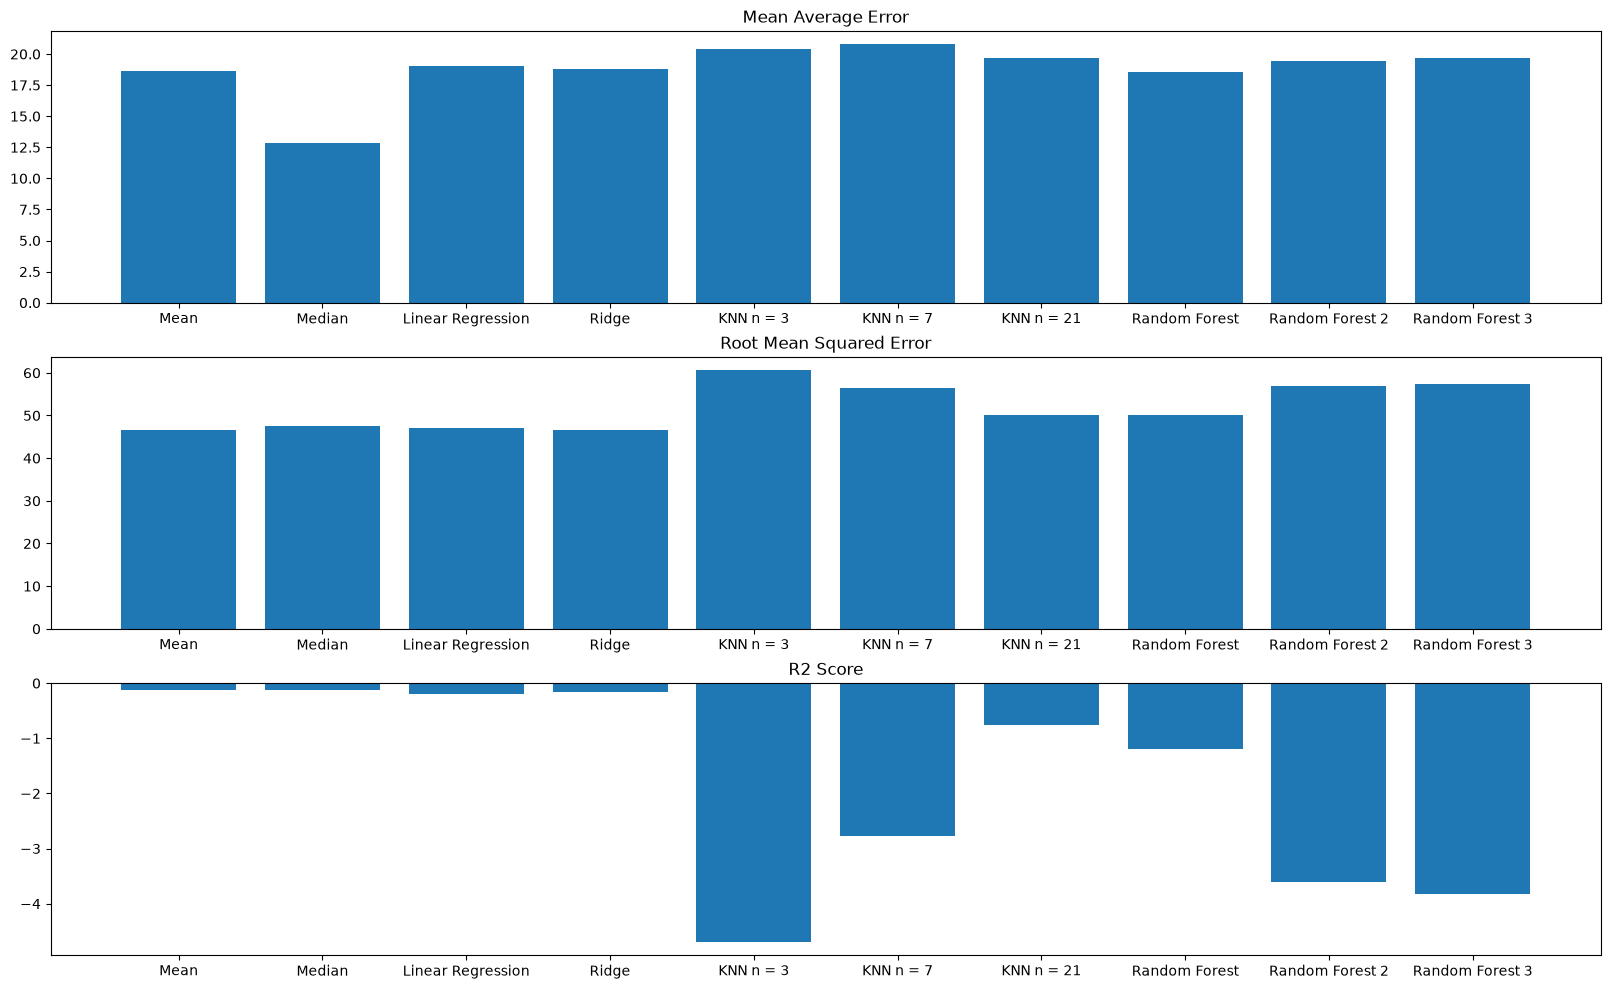

In [20]:
from sklearn.model_selection import cross_validate, RepeatedKFold
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
#Split the data
X = df[categorical_columns + numerical_columns]
y = np.log1p(np.log1p(df["area"]))

# Trying Different Models and preprocessing pipelines using cross validation

cv = RepeatedKFold(n_splits=10, n_repeats=3, random_state=RANDOM_STATE)

for title, preprocessing in preprocessing_pipelines.items():
    print("--------------PREPROCESSING: ", title,"--------------")

    resultsMAE =[]
    resultsRMSE = []
    resultsR2 = []
    #Run all of the models and print out their results
    for name, model in models.items():
        model = make_pipeline(preprocessing, model)
        results = cross_validate(
            model, X, np.expm1(np.expm1(y)), 
            cv=cv,
            scoring={"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2":"r2"},
            return_train_score=True
        )

        mae = -results["test_mae"].mean()
        rmse = -results["test_rmse"].mean()
        r2 = results["test_r2"].mean()
    
        resultsMAE.append(mae)
        resultsRMSE.append(rmse)
        resultsR2.append(r2)
    
        print("Model: ", name ,"\nMean Absolute Error: ", mae, "\nRoot Mean Squared Error: ", rmse,"\nR2 Score: ", r2 ,"\n\n")

    #Plot Results
    plt.figure(figsize={len(models.keys()) * 2,12}) #Figure is dynamically sized to allow for more models to be added as needed
    
    plt.subplot(311, title="Mean Average Error").bar(range(len(resultsMAE)),resultsMAE)
    plt.xticks(range(len(models.keys())),models.keys())
    
    plt.subplot(312, title="Root Mean Squared Error").bar(range(len(resultsRMSE)),resultsRMSE)
    plt.xticks(range(len(models.keys())),models.keys())
    
    plt.subplot(313, title="R2 Score").bar(range(len(resultsR2)),resultsR2)
    plt.xticks(range(len(models.keys())),models.keys())

    plt.show()

--------------PREPROCESSING:  ALL --------------
Model:  Mean 
Mean Absolute Error:  18.601950948884948 
Root Mean Squared Error:  46.59387426339114 
R2 Score:  -0.11840109852428118 


Model:  Median 
Mean Absolute Error:  12.844220085470091 
Root Mean Squared Error:  47.55444633886254 
R2 Score:  -0.12741721353976457 


Model:  Linear Regression 
Mean Absolute Error:  21.911640601884447 
Root Mean Squared Error:  49.5869109227956 
R2 Score:  -0.6669147869298209 


Model:  Ridge 
Mean Absolute Error:  19.497670181465374 
Root Mean Squared Error:  47.614962056960636 
R2 Score:  -0.31859027235413395 


Model:  KNN n = 3 
Mean Absolute Error:  21.31807771912185 
Root Mean Squared Error:  60.85146047845941 
R2 Score:  -3.737250145853587 


Model:  KNN n = 7 
Mean Absolute Error:  20.05388914027151 
Root Mean Squared Error:  54.49169900056805 
R2 Score:  -1.6191345453441424 


Model:  KNN n = 21 
Mean Absolute Error:  19.628108818741183 
Root Mean Squared Error:  50.1509570595459 
R2 Score:

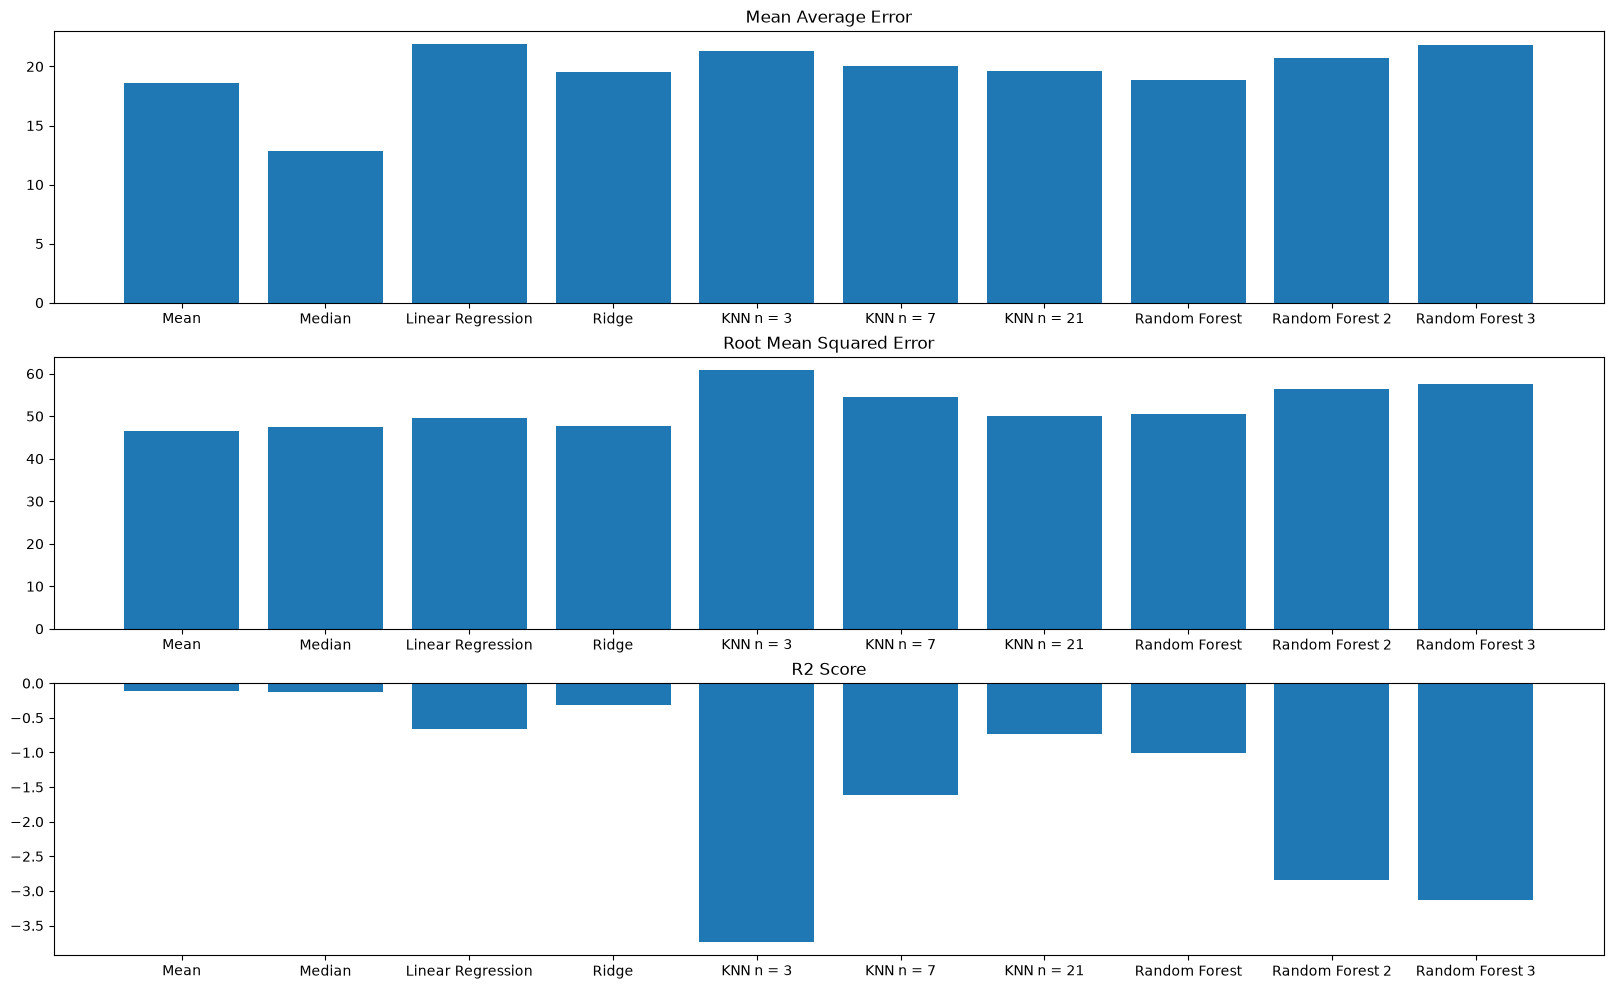

--------------PREPROCESSING:  FIRE WEATHER INDEX ONLY --------------
Model:  Mean 
Mean Absolute Error:  18.601950948884948 
Root Mean Squared Error:  46.59387426339114 
R2 Score:  -0.11840109852428118 


Model:  Median 
Mean Absolute Error:  12.844220085470091 
Root Mean Squared Error:  47.55444633886254 
R2 Score:  -0.12741721353976457 


Model:  Linear Regression 
Mean Absolute Error:  19.06754069608248 
Root Mean Squared Error:  47.01533088335652 
R2 Score:  -0.19815277373234377 


Model:  Ridge 
Mean Absolute Error:  18.776508847136522 
Root Mean Squared Error:  46.70365023266131 
R2 Score:  -0.15716489134618683 


Model:  KNN n = 3 
Mean Absolute Error:  20.446447628624114 
Root Mean Squared Error:  60.66424971937213 
R2 Score:  -4.694377897276357 


Model:  KNN n = 7 
Mean Absolute Error:  20.819556920203993 
Root Mean Squared Error:  56.35431038773827 
R2 Score:  -2.7719135424285173 


Model:  KNN n = 21 
Mean Absolute Error:  19.64617591994064 
Root Mean Squared Error:  50.205

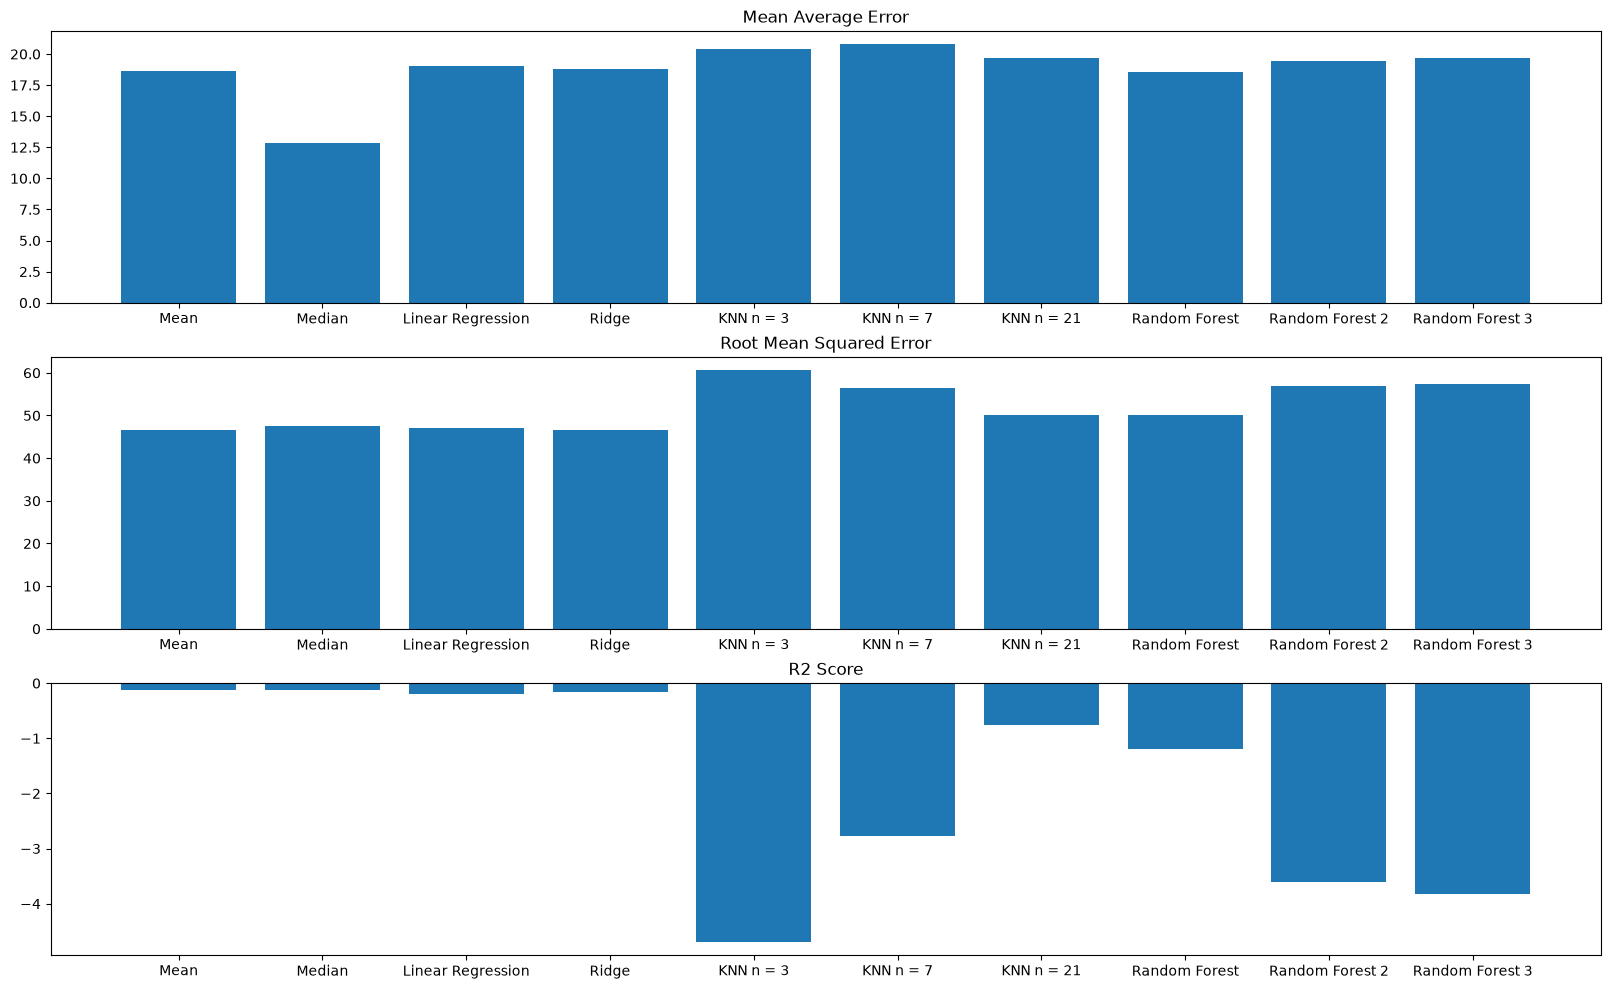

In [20]:
from sklearn.model_selection import cross_validate, RepeatedKFold
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
#Split the data
X = df[categorical_columns + numerical_columns]
y = np.log1p(np.log1p(df["area"]))

# Trying Different Models and preprocessing pipelines using cross validation

cv = RepeatedKFold(n_splits=10, n_repeats=3, random_state=RANDOM_STATE)

for title, preprocessing in preprocessing_pipelines.items():
    print("--------------PREPROCESSING: ", title,"--------------")

    resultsMAE =[]
    resultsRMSE = []
    resultsR2 = []
    #Run all of the models and print out their results
    for name, model in models.items():
        model = make_pipeline(preprocessing, model)
        results = cross_validate(
            model, X, np.expm1(np.expm1(y)), 
            cv=cv,
            scoring={"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2":"r2"},
            return_train_score=True
        )

        mae = -results["test_mae"].mean()
        rmse = -results["test_rmse"].mean()
        r2 = results["test_r2"].mean()
    
        resultsMAE.append(mae)
        resultsRMSE.append(rmse)
        resultsR2.append(r2)
    
        print("Model: ", name ,"\nMean Absolute Error: ", mae, "\nRoot Mean Squared Error: ", rmse,"\nR2 Score: ", r2 ,"\n\n")

    #Plot Results
    plt.figure(figsize={len(models.keys()) * 2,12}) #Figure is dynamically sized to allow for more models to be added as needed
    
    plt.subplot(311, title="Mean Average Error").bar(range(len(resultsMAE)),resultsMAE)
    plt.xticks(range(len(models.keys())),models.keys())
    
    plt.subplot(312, title="Root Mean Squared Error").bar(range(len(resultsRMSE)),resultsRMSE)
    plt.xticks(range(len(models.keys())),models.keys())
    
    plt.subplot(313, title="R2 Score").bar(range(len(resultsR2)),resultsR2)
    plt.xticks(range(len(models.keys())),models.keys())

    plt.show()

Results for 10 splits and 3 repeats
--------------PREPROCESSING:  ALL --------------
Model:  Mean 
Mean Absolute Error:  18.601950948884948 
Root Mean Squared Error:  46.59387426339114 
R2 Score:  -0.11840109852428118 


Model:  Median 
Mean Absolute Error:  12.844220085470091 
Root Mean Squared Error:  47.55444633886254 
R2 Score:  -0.12741721353976457 


Model:  Linear Regression 
Mean Absolute Error:  21.911640601884447 
Root Mean Squared Error:  49.5869109227956 
R2 Score:  -0.6669147869298209 


Model:  Ridge 
Mean Absolute Error:  19.497670181465374 
Root Mean Squared Error:  47.614962056960636 
R2 Score:  -0.31859027235413395 


Model:  KNN n = 3 
Mean Absolute Error:  21.31807771912185 
Root Mean Squared Error:  60.85146047845941 
R2 Score:  -3.737250145853587 


Model:  KNN n = 7 
Mean Absolute Error:  20.05388914027151 
Root Mean Squared Error:  54.49169900056805 
R2 Score:  -1.6191345453441424 


Model:  KNN n = 21 
Mean Absolute Error:  19.628108818741183 
Root Mean Squared Error:  50.1509570595459 
R2 Score:  -0.7406209798756176 


Model:  Random Forest 
Mean Absolute Error:  18.848172144322636 
Root Mean Squared Error:  50.57918231679592 
R2 Score:  -1.0122261358392046 


Model:  Random Forest 2 
Mean Absolute Error:  20.75287456414077 
Root Mean Squared Error:  56.466871515305435 
R2 Score:  -2.836364372868674 


Model:  Random Forest 3 
Mean Absolute Error:  21.779987175825173 
Root Mean Squared Error:  57.554151139078904 
R2 Score:  -3.1313067902131357 



--------------PREPROCESSING:  FIRE WEATHER INDEX ONLY --------------
Model:  Mean 
Mean Absolute Error:  18.601950948884948 
Root Mean Squared Error:  46.59387426339114 
R2 Score:  -0.11840109852428118 


Model:  Median 
Mean Absolute Error:  12.844220085470091 
Root Mean Squared Error:  47.55444633886254 
R2 Score:  -0.12741721353976457 


Model:  Linear Regression 
Mean Absolute Error:  19.06754069608248 
Root Mean Squared Error:  47.01533088335652 
R2 Score:  -0.19815277373234377 


Model:  Ridge 
Mean Absolute Error:  18.776508847136522 
Root Mean Squared Error:  46.70365023266131 
R2 Score:  -0.15716489134618683 


Model:  KNN n = 3 
Mean Absolute Error:  20.446447628624114 
Root Mean Squared Error:  60.66424971937213 
R2 Score:  -4.694377897276357 


Model:  KNN n = 7 
Mean Absolute Error:  20.819556920203993 
Root Mean Squared Error:  56.35431038773827 
R2 Score:  -2.7719135424285173 


Model:  KNN n = 21 
Mean Absolute Error:  19.64617591994064 
Root Mean Squared Error:  50.2054055758376 
R2 Score:  -0.7509843308947544 


Model:  Random Forest 
Mean Absolute Error:  18.59493105985581 
Root Mean Squared Error:  50.188579024440244 
R2 Score:  -1.1948374165880122 


Model:  Random Forest 2 
Mean Absolute Error:  19.415002187145483 
Root Mean Squared Error:  56.921558033543754 
R2 Score:  -3.6066098652453773 


Model:  Random Forest 3 
Mean Absolute Error:  19.687095076645452 
Root Mean Squared Error:  57.48947998355303 
R2 Score:  -3.825960837353941 



Results for 10 splits and 30 repeats
--------------PREPROCESSING:  ALL --------------
Model:  Mean 
Mean Absolute Error:  18.609668428028673 
Root Mean Squared Error:  45.381608788309656 
R2 Score:  -0.25867062376912014 


Model:  Median 
Mean Absolute Error:  12.842453946706888 
Root Mean Squared Error:  46.05468943821839 
R2 Score:  -0.13192394242870478 


Model:  Linear Regression 
Mean Absolute Error:  21.93288837823196 
Root Mean Squared Error:  48.371339759500124 
R2 Score:  -1.063897937657315 


Model:  Ridge 
Mean Absolute Error:  19.49937864158169 
Root Mean Squared Error:  46.36217392666987 
R2 Score:  -0.5394065506547565 


Model:  KNN n = 3 
Mean Absolute Error:  22.013880153343393 
Root Mean Squared Error:  63.294525773696826 
R2 Score:  -7.342262129881788 


Model:  KNN n = 7 
Mean Absolute Error:  20.390680884148537 
Root Mean Squared Error:  54.865648988347736 
R2 Score:  -3.105922691638094 


Model:  KNN n = 21 
Mean Absolute Error:  19.884015219421105 
Root Mean Squared Error:  49.44119912848301 
R2 Score:  -1.331089432972221 


Model:  Random Forest 
Mean Absolute Error:  18.776097671256444 
Root Mean Squared Error:  48.35883763227527 
R2 Score:  -0.9511579900079838 


Model:  Random Forest 2 
Mean Absolute Error:  20.870042826009364 
Root Mean Squared Error:  54.52764100852909 
R2 Score:  -2.9626220006503097 


Model:  Random Forest 3 
Mean Absolute Error:  21.707410588208514 
Root Mean Squared Error:  55.2348588757244 
R2 Score:  -3.2802391411569722 



--------------PREPROCESSING:  FIRE WEATHER INDEX ONLY --------------
Model:  Mean 
Mean Absolute Error:  18.609668428028673 
Root Mean Squared Error:  45.381608788309656 
R2 Score:  -0.25867062376912014 


Model:  Median 
Mean Absolute Error:  12.842453946706888 
Root Mean Squared Error:  46.05468943821839 
R2 Score:  -0.13192394242870478 


Model:  Linear Regression 
Mean Absolute Error:  19.152612580796035 
Root Mean Squared Error:  45.84615611790934 
R2 Score:  -0.3743500768341501 


Model:  Ridge 
Mean Absolute Error:  18.825952287531198 
Root Mean Squared Error:  45.549567542024995 
R2 Score:  -0.32157004117454213 


Model:  KNN n = 3 
Mean Absolute Error:  20.37759969834088 
Root Mean Squared Error:  58.886579728337324 
R2 Score:  -5.064512582919155 


Model:  KNN n = 7 
Mean Absolute Error:  20.7827052233714 
Root Mean Squared Error:  54.810128557409385 
R2 Score:  -3.2746373861444877 


Model:  KNN n = 21 
Mean Absolute Error:  19.36560334159305 
Root Mean Squared Error:  48.61583185729419 
R2 Score:  -1.0233387220490184 


Model:  Random Forest 
Mean Absolute Error:  18.63491566210044 
Root Mean Squared Error:  48.33809239338372 
R2 Score:  -1.242966688022119 


Model:  Random Forest 2 
Mean Absolute Error:  19.32133337463193 
Root Mean Squared Error:  54.69207567031704 
R2 Score:  -3.4234055046150655 


Model:  Random Forest 3 
Mean Absolute Error:  19.756267556183513 
Root Mean Squared Error:  55.45635446386324 
R2 Score:  -3.730450613932852 


